In [2]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [3]:
m=tf.keras.datasets.mnist

In [4]:
(x_train, y_train),(x_test,y_test)=m.load_data()
x_train,x_test = x_train/255, x_test/255

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("\nTesting images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)

Testing images: (10000, 28, 28)
Testing labels: (10000,)


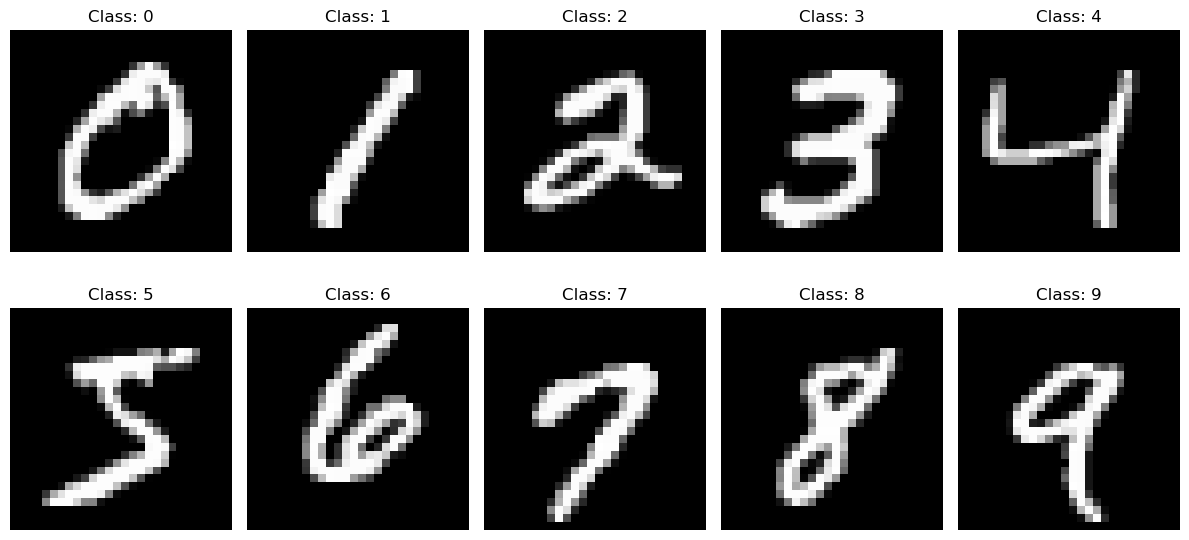

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for digit in range(10):
    # Find the first image belonging to this digit
    index = list(y_train).index(digit)

    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap='gray')
    plt.title(f"Class: {digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
model = tf.keras.models.Sequential([
    
tf.keras.layers.Flatten(input_shape=(28,28)),
tf.keras.layers.Dense(512, activation='relu'),
tf.keras.layers.Dropout(0.2),
tf.keras.layers.Dense(10, activation ='softmax')
])

In [9]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [8]:
history = model.fit(x_train,y_train,epochs=5, validation_split=0.2)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9275 - loss: 0.2444 - val_accuracy: 0.9575 - val_loss: 0.1366
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9686 - loss: 0.1041 - val_accuracy: 0.9706 - val_loss: 0.1001
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9761 - loss: 0.0754 - val_accuracy: 0.9751 - val_loss: 0.0817
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9837 - loss: 0.0538 - val_accuracy: 0.9751 - val_loss: 0.0875
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9849 - loss: 0.0463 - val_accuracy: 0.9766 - val_loss: 0.0808


In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9813 - loss: 0.0635   
Test Loss: 0.0634559914469719
Test Accuracy: 98.12999963760376 %


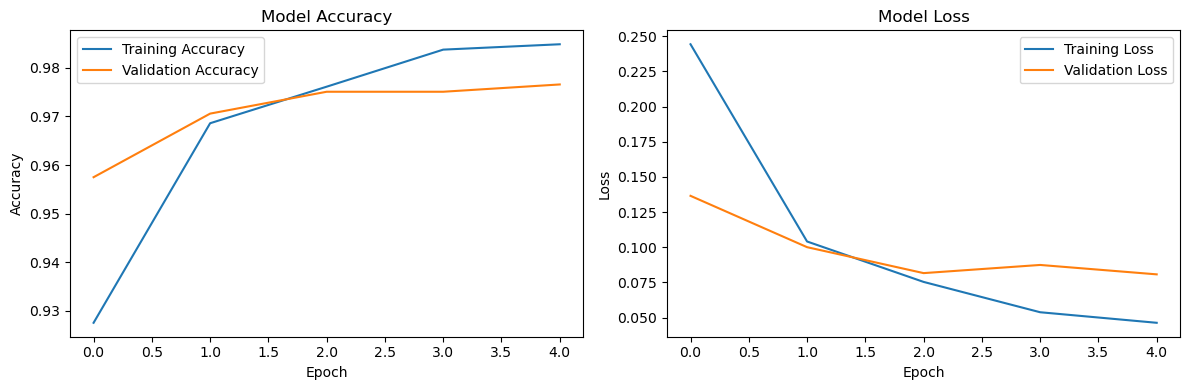

In [11]:
import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
model.save('MNIST_model.keras')
print("Succesfully saved")

Succesfully saved
